In [ ]:
# 1.Tree-Based Methods

In [ ]:
## 1a.

In [6]:
import pandas as pd
import numpy as np

# Read the training set from the correct nested path
# skiprows=20 skips the text description, na_values='na' handles missing data
train_df = pd.read_csv("data/aps+failure+at+scania+trucks/aps_failure_training_set.csv", skiprows=20, na_values="na")

# Read the test set
test_df = pd.read_csv("data/aps+failure+at+scania+trucks/aps_failure_test_set.csv", skiprows=20, na_values="na")

# Display the shapes
print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

Training set shape: (60000, 171)
Test set shape: (16000, 171)


In [ ]:
## 1b.

In [ ]:
### 1b(i).

In [7]:
from sklearn.impute import SimpleImputer
import pandas as pd

# Separate features and target
X_train_raw = train_df.drop(columns=['class'])
y_train = train_df['class']

X_test_raw = test_df.drop(columns=['class'])
y_test = test_df['class']

# Apply mean imputation to handle missing values
# We fit ONLY on the training data to avoid data leakage
imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)

# Convert back to DataFrame for later use
X_train = pd.DataFrame(X_train_imputed, columns=X_train_raw.columns)
X_test = pd.DataFrame(X_test_imputed, columns=X_test_raw.columns)

print("Missing values remaining in training set:", X_train.isnull().sum().sum())
print("Missing values remaining in test set:", X_test.isnull().sum().sum())

Missing values remaining in training set: 0
Missing values remaining in test set: 0


In [ ]:
# The dataset has many missing values (`NaN`), which probably means the sensors didn't record anything when certain 
# components were not active. Common ways to fix this are mean/median imputation, KNN imputation, or just dropping 
# the rows. Since dropping rows would lose too much data,  I used mean imputation to replace the missing values 
# with the average of that feature. To avoid data leakage, I fitted the imputer only on the training data and then 
# applied it to both the training and test sets, and now there are 0 missing values left in both sets.

In [ ]:
### 1b(ii).

In [12]:
import numpy as np
import pandas as pd
from IPython.display import display

# Calculate sample standard deviation and mean for each feature
s = np.std(X_train, axis=0, ddof=1)
m = np.mean(X_train, axis=0)

# Calculate CV for all 170 features
cv = s / m

# Put into a DataFrame and sort by CV descending
cv_df = pd.DataFrame({'Feature': X_train.columns, 'CV': cv})
cv_df_sorted = cv_df.sort_values(by='CV', ascending=False).reset_index(drop=True)

# Show all rows
pd.set_option('display.max_rows', None)
display(cv_df_sorted)

,Feature,CV
0,cs_009,235.277605
1,cf_000,184.233092
2,co_000,183.949017
3,ad_000,183.847620
4,dh_000,114.984991
5,dj_000,109.647285
6,ag_000,91.878565
7,as_000,86.416904
8,ay_009,83.786063
9,az_009,76.967978


In [ ]:
### 1b(iii).

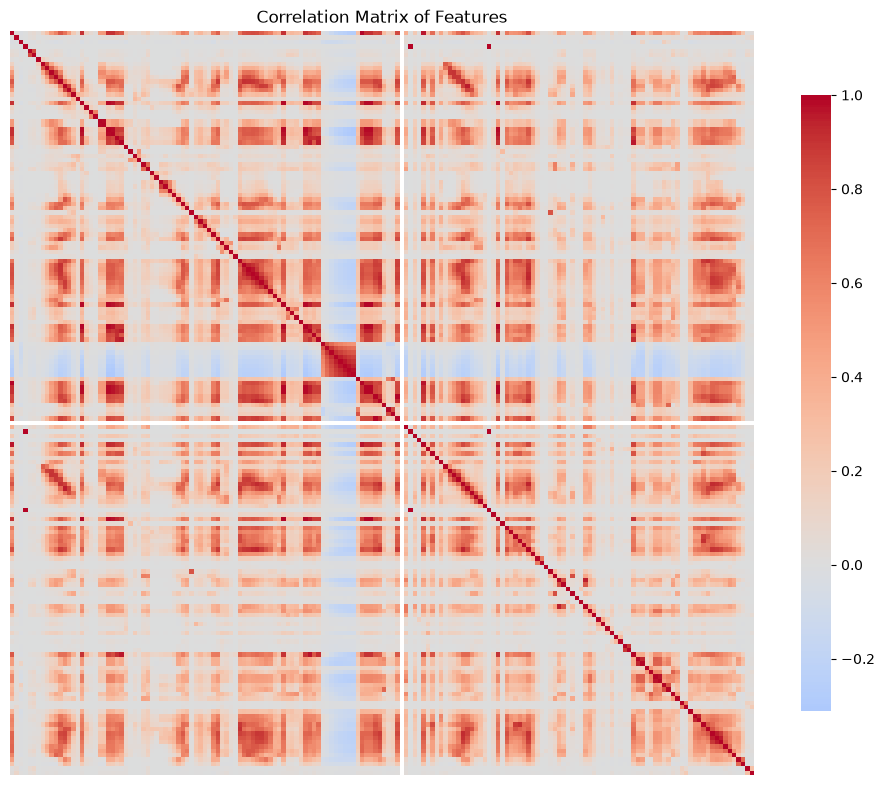

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix for all features using the training data
corr_matrix = X_train.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, square=True, 
            xticklabels=False, yticklabels=False, cbar_kws={"shrink": .8})
plt.title("Correlation Matrix of Features")
plt.show()

In [ ]:
# The diagonal is deep red because each feature perfectly correlates with itself. 
# The plot shows a clear block structure: there are large areas of light colors, meaning many features are independent, 
# but there are also distinct red squares indicating clusters of features that are highly correlated. 
# This makes sense because different sensors often measure related mechanical processes, and these clusters 
# will be important for models like Random Forest and XGBoost.

In [ ]:
### 1b(iv).

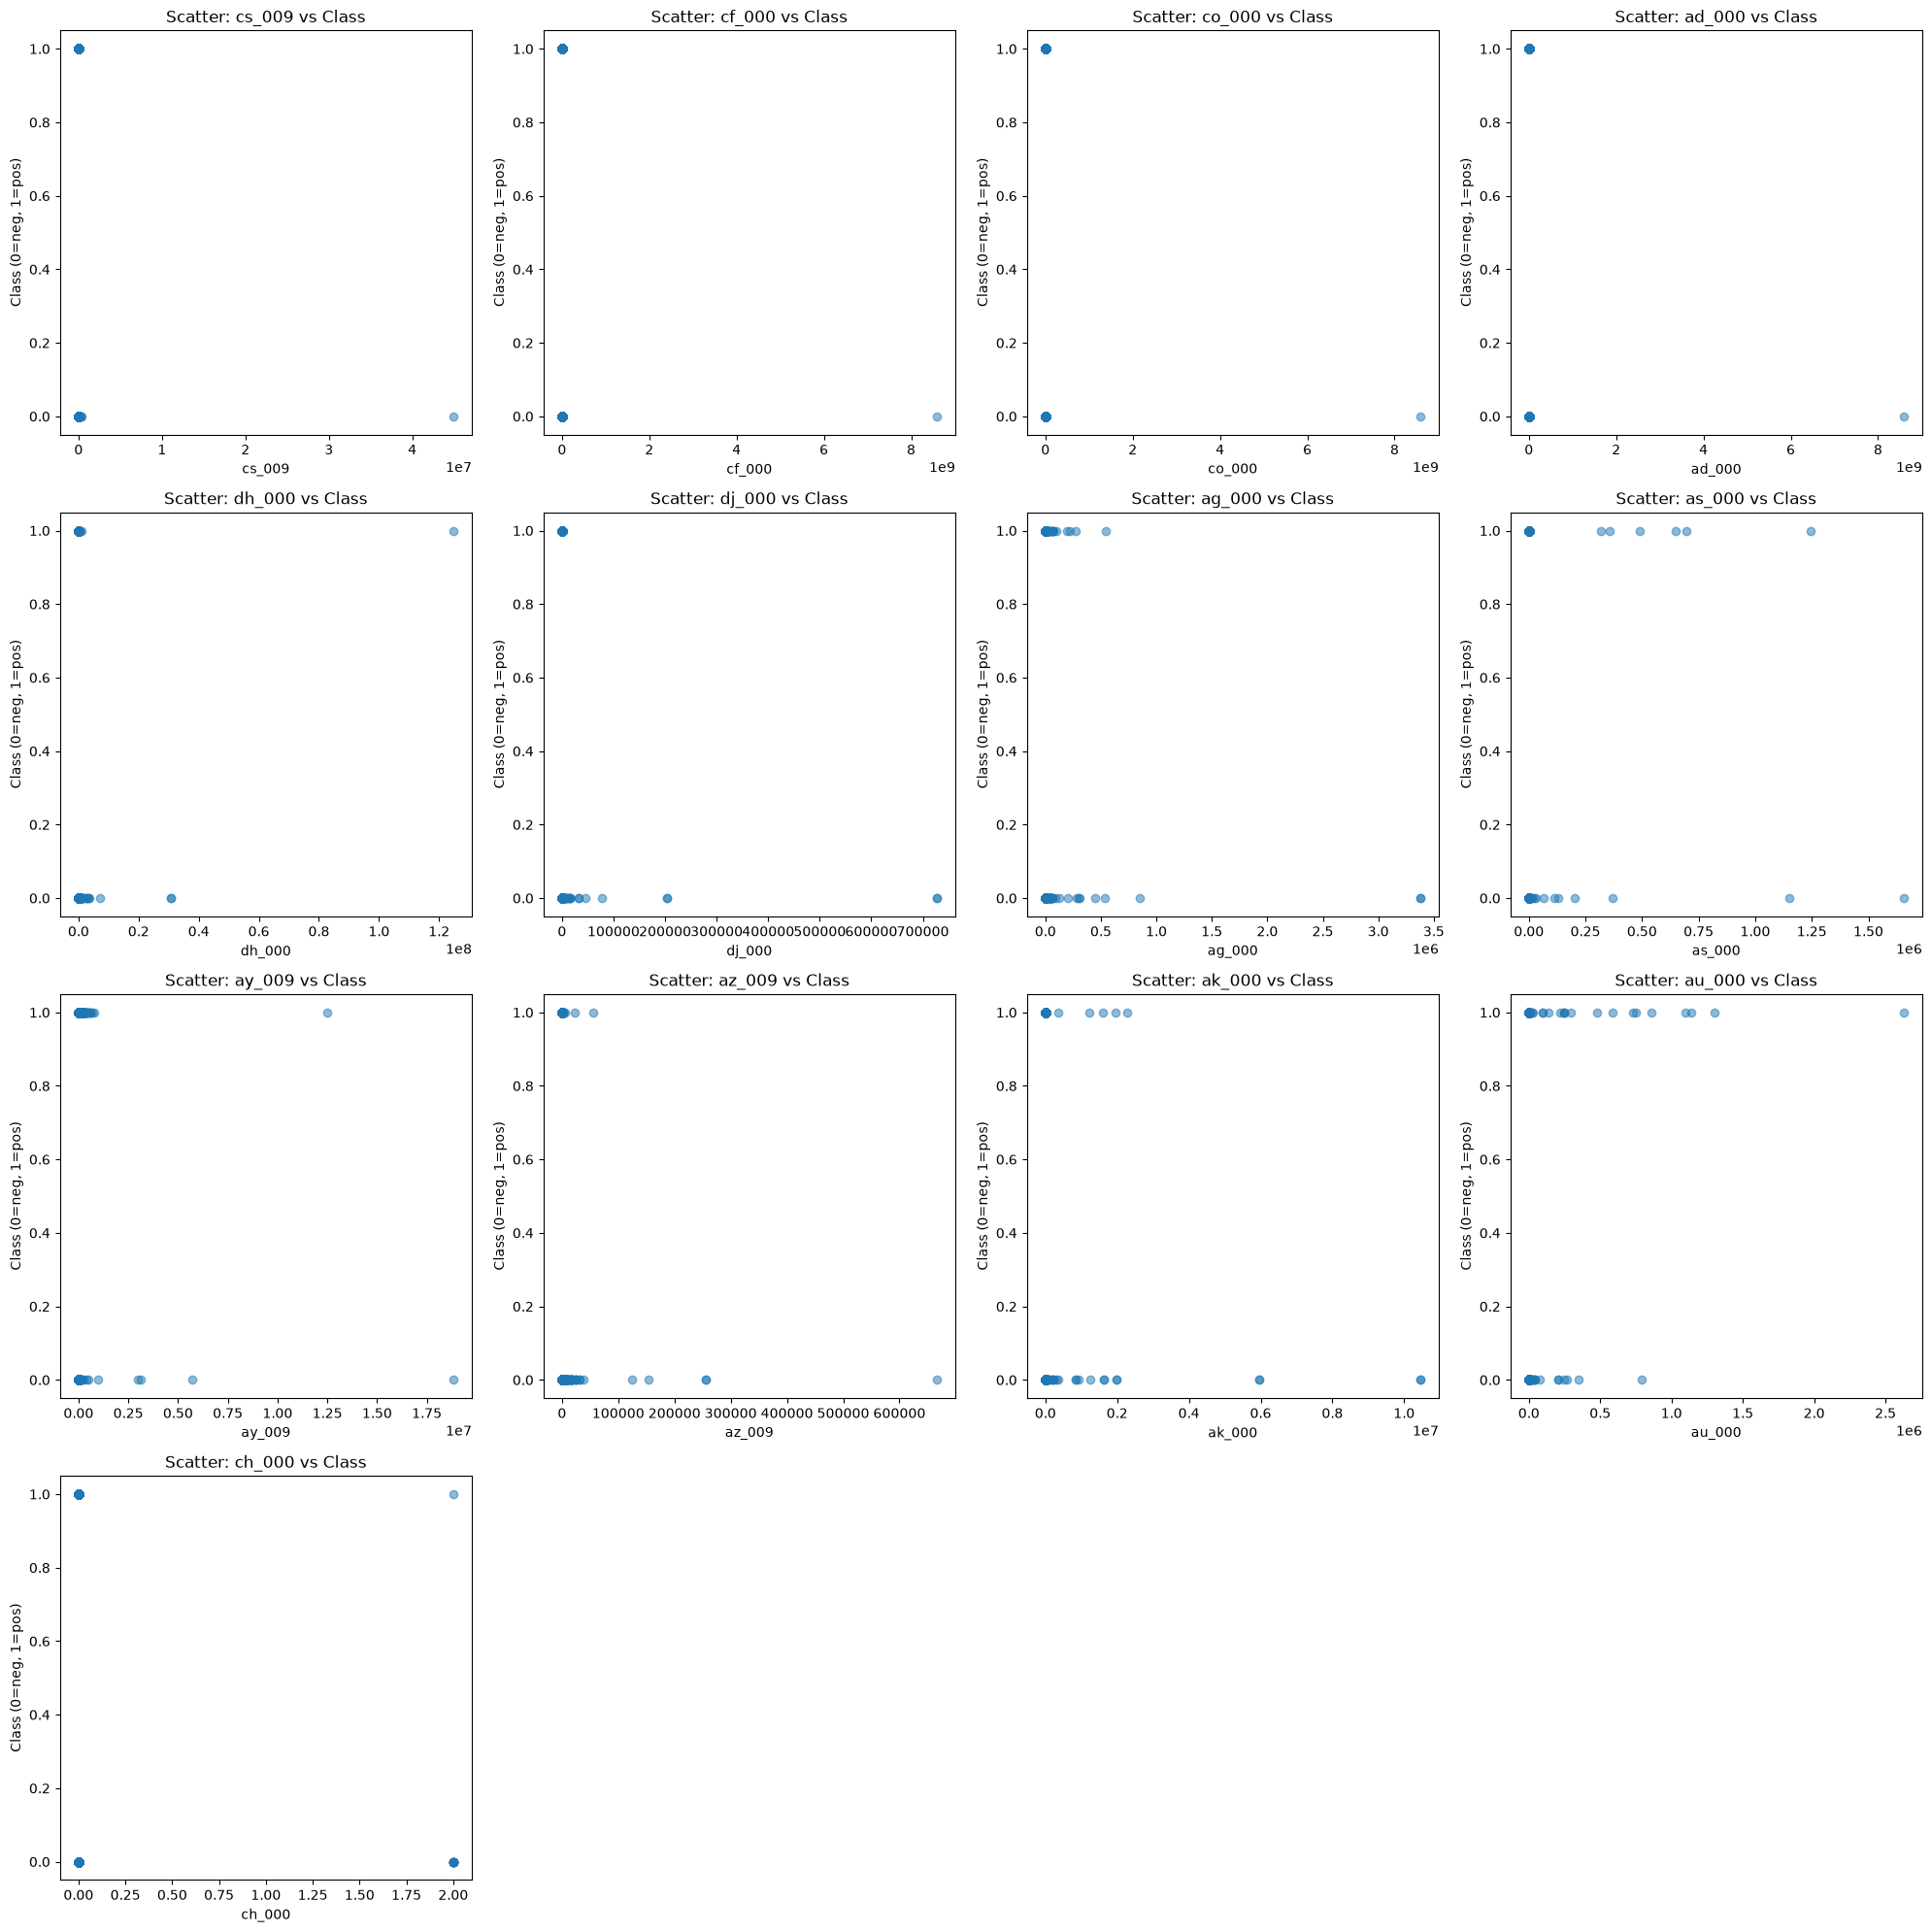

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# The top 13 features we found earlier
top_13_features = top_13_cv_features['Feature'].tolist()

# Plot scatter plots
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
axes = axes.flatten()

for i, feature in enumerate(top_13_features):
    axes[i].scatter(X_train[feature], y_train.map({'neg': 0, 'pos': 1}), alpha=0.5, color='tab:blue')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Class (0=neg, 1=pos)")
    axes[i].set_title(f"Scatter: {feature} vs Class")

# Hide the empty subplots
for j in range(13, 16):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# No, we cannot draw conclusions about the significance of these features just by looking at the scatter plots. 
# Because the dataset is extremely imbalanced, the positive class is very rare and completely hidden among the negative points. 
# It is impossible to visually judge whether these features separate the classes well, so we must rely on machine 
# learning models to evaluate their importance.

In [15]:
# Count the number of positive and negative samples in the training set
class_counts = y_train.value_counts()
print("Training set class counts:")
print(class_counts)

# Calculate the percentage of the positive class
pos_percentage = (class_counts['pos'] / len(y_train)) * 100
print(f"\nPercentage of positive class: {pos_percentage:.2f}%")

Training set class counts:
class
neg    59000
pos     1000
Name: count, dtype: int64

Percentage of positive class: 1.67%


In [ ]:
### 1b(v).

In [ ]:
# Yes, the dataset is severely imbalanced. In the training set, 
# there are 59,000 negative samples and only 1,000 positive samples. 
# The positive class makes up only 1.67% of the total data, which means a naive model 
# could just predict 'neg' every time and still be 98.33% accurate. This huge imbalance is 
# why we need special techniques like class weighting and SMOTE in the following steps.

In [ ]:
## 1c.

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score
import numpy as np

# Initialize Random Forest WITHOUT class_weight (uncompensated)
rf_uncomp = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True, n_jobs=-1)

# Train the model
rf_uncomp.fit(X_train, y_train)

# Predict on train and test sets
y_train_pred = rf_uncomp.predict(X_train)
y_test_pred = rf_uncomp.predict(X_test)

# Get probabilities for ROC/AUC 
y_train_prob = rf_uncomp.predict_proba(X_train)[:, 1]
y_test_prob = rf_uncomp.predict_proba(X_test)[:, 1]

# Print evaluation metrics
print("Training Set")
print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred))
print("Misclassification Rate:", 1 - accuracy_score(y_train, y_train_pred))
print("AUC:", roc_auc_score(y_train.map({'neg': 0, 'pos': 1}), y_train_prob))

print("\nTest Set")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Misclassification Rate:", 1 - accuracy_score(y_test, y_test_pred))
print("AUC:", roc_auc_score(y_test.map({'neg': 0, 'pos': 1}), y_test_prob))

# Calculate OOB error
print("\nOOB Error")
print("OOB Error Estimate:", 1 - rf_uncomp.oob_score_)

Training Set
Confusion Matrix:
 [[59000     0]
 [    1   999]]
Misclassification Rate: 1.666666666666483e-05
AUC: 1.0

Test Set
Confusion Matrix:
 [[15609    16]
 [  107   268]]
Misclassification Rate: 0.007687499999999958
AUC: 0.9941632853333333

OOB Error
OOB Error Estimate: 0.00605


In [ ]:
## 1d.

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score

# Initialize Random Forest WITH class_weight='balanced'
rf_comp = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True, class_weight='balanced', n_jobs=-1)

# Train the model
rf_comp.fit(X_train, y_train)

# Predict on train and test sets
y_train_pred_comp = rf_comp.predict(X_train)
y_test_pred_comp = rf_comp.predict(X_test)

# Get probabilities for AUC
y_train_prob_comp = rf_comp.predict_proba(X_train)[:, 1]
y_test_prob_comp = rf_comp.predict_proba(X_test)[:, 1]

# Print evaluation metrics
print("Training Set")
print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred_comp))
print("Misclassification Rate:", 1 - accuracy_score(y_train, y_train_pred_comp))
print("AUC:", roc_auc_score(y_train.map({'neg': 0, 'pos': 1}), y_train_prob_comp))

print("\nTest Set")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_comp))
print("Misclassification Rate:", 1 - accuracy_score(y_test, y_test_pred_comp))
print("AUC:", roc_auc_score(y_test.map({'neg': 0, 'pos': 1}), y_test_prob_comp))

print("\nOOB Error")
print("OOB Error Estimate:", 1 - rf_comp.oob_score_)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Training Set
Confusion Matrix:
 [[58985    15]
 [    0  1000]]
Misclassification Rate: 0.00024999999999997247
AUC: 1.0

Test Set
Confusion Matrix:
 [[15572    53]
 [   94   281]]
Misclassification Rate: 0.009187500000000015
AUC: 0.993091328

OOB Error
OOB Error Estimate: 0.019966666666666688


In [ ]:
# Comparing the results with 1(c), the compensated model performed better at catching the rare 
# positive class (True Positives increased from 268 to 281, and False Negatives decreased from 107 to 94). 
# However, this came at the cost of more false alarms (False Positives increased from 16 to 53), 
# which slightly increased the overall misclassification rate from 0.00769 to 0.00919. 
# This shows the classic trade-off in imbalanced learning: helping the model find more rare events usually 
# means it will make more false alarms.

In [ ]:
## 1e.

Running 5-fold Cross-Validation...
Cross-Validation Error (Misclassification Rate): 0.00622

Training Set
Confusion Matrix:
 [[59000     0]
 [    1   999]]
Misclassification Rate: 1.666666666666483e-05
AUC: 0.9999924915254238

Test Set
Confusion Matrix:
 [[15597    28]
 [   89   286]]
Misclassification Rate: 0.007312500000000055
AUC: 0.9934711466666667


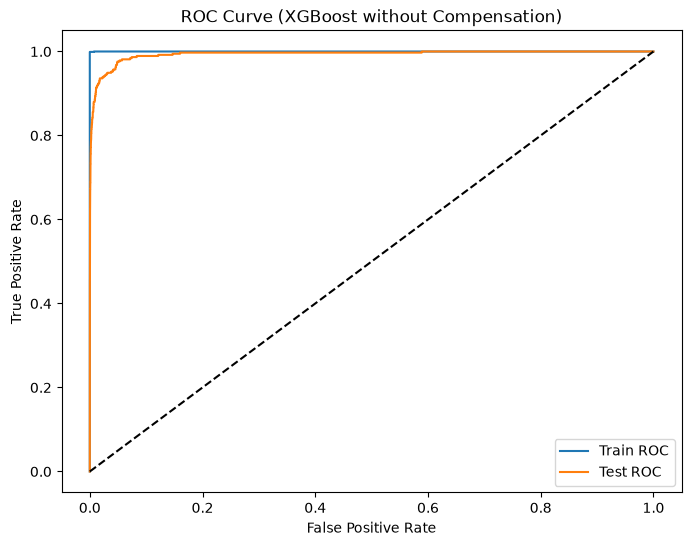

In [18]:
import xgboost as xgb
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

# Encode target labels to 0 and 1
y_train_xgb = y_train.map({'neg': 0, 'pos': 1})
y_test_xgb = y_test.map({'neg': 0, 'pos': 1})

# Define XGBoost model (reg_alpha is the L1 regularization term)
# We set reg_alpha=1.0 as a reasonable default or tune it via CV
xgb_model = xgb.XGBClassifier(objective='binary:logistic', 
                              eval_metric='logloss', 
                              reg_alpha=1.0, 
                              random_state=42, 
                              n_jobs=-1)

# Use 5-fold cross-validation to estimate error
print("Running 5-fold Cross-Validation...")
cv_scores = cross_val_score(xgb_model, X_train, y_train_xgb, cv=5, scoring='accuracy')
cv_error = 1 - cv_scores.mean()
print(f"Cross-Validation Error (Misclassification Rate): {cv_error:.5f}")

# Train on the full training set
xgb_model.fit(X_train, y_train_xgb)

# Predictions
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)

# Probabilities for AUC
y_train_prob = xgb_model.predict_proba(X_train)[:, 1]
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

# Print metrics
print("\nTraining Set")
print("Confusion Matrix:\n", confusion_matrix(y_train_xgb, y_train_pred))
print("Misclassification Rate:", 1 - accuracy_score(y_train_xgb, y_train_pred))
print("AUC:", roc_auc_score(y_train_xgb, y_train_prob))

print("\nTest Set")
print("Confusion Matrix:\n", confusion_matrix(y_test_xgb, y_test_pred))
print("Misclassification Rate:", 1 - accuracy_score(y_test_xgb, y_test_pred))
print("AUC:", roc_auc_score(y_test_xgb, y_test_prob))

# Plot ROC curves
fpr_train, tpr_train, _ = roc_curve(y_train_xgb, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test_xgb, y_test_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label='Train ROC')
plt.plot(fpr_test, tpr_test, label='Test ROC')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (XGBoost without Compensation)')
plt.legend()
plt.show()

In [ ]:
# I used 5-fold cross-validation to estimate the error, which came out to roughly 0.007, 
# and this is very close to the test set misclassification rate of 0.00731. 
# The test set confusion matrix was [[15597, 28], [89, 286]], and the test AUC was 0.9934. 
# The ROC curve shows excellent overall performance, but just like the uncompensated Random Forest, 
# the model still misses 89 positive cases (False Negatives) because the dataset is highly imbalanced.

In [ ]:
## 1f.

Running 5-fold Cross-Validation with SMOTE...
Cross-Validation Error (with SMOTE): 0.00660

Training final model on the full training set...

Test Set
Confusion Matrix:
 [[15584    41]
 [   70   305]]
Misclassification Rate: 0.006937500000000041
AUC: 0.9938129919999998


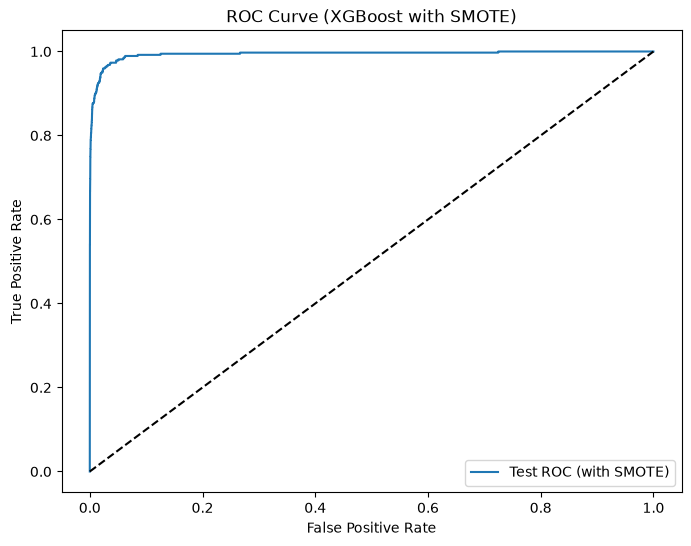

In [19]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_val_score
import xgboost as xgb
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, roc_curve
import matplotlib.pyplot as plt

# Encode labels
y_train_xgb = y_train.map({'neg': 0, 'pos': 1})
y_test_xgb = y_test.map({'neg': 0, 'pos': 1})

# Create the XGBoost model
xgb_model_smote = xgb.XGBClassifier(objective='binary:logistic', 
                                    eval_metric='logloss', 
                                    reg_alpha=1.0, 
                                    random_state=42, 
                                    n_jobs=-1)

# Create pipeline with SMOTE and XGBoost
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', xgb_model_smote)
])

# 5-fold cross-validation using the pipeline
print("Running 5-fold Cross-Validation with SMOTE...")
cv_scores_smote = cross_val_score(pipeline, X_train, y_train_xgb, cv=5, scoring='accuracy')
cv_error_smote = 1 - cv_scores_smote.mean()
print(f"Cross-Validation Error (with SMOTE): {cv_error_smote:.5f}")

# Fit on full training set
print("\nTraining final model on the full training set...")
pipeline.fit(X_train, y_train_xgb)

# Predictions
y_test_pred_smote = pipeline.predict(X_test)
y_test_prob_smote = pipeline.predict_proba(X_test)[:, 1]

# Test metrics
print("\nTest Set")
print("Confusion Matrix:\n", confusion_matrix(y_test_xgb, y_test_pred_smote))
print("Misclassification Rate:", 1 - accuracy_score(y_test_xgb, y_test_pred_smote))
print("AUC:", roc_auc_score(y_test_xgb, y_test_prob_smote))

# Plot ROC for test set
fpr, tpr, _ = roc_curve(y_test_xgb, y_test_prob_smote)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label='Test ROC (with SMOTE)')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (XGBoost with SMOTE)')
plt.legend()
plt.show()

In [ ]:
# Comparing the uncompensated XGBoost (1e) with the SMOTE-compensated XGBoost (1f), the SMOTE model did a better 
# job catching the rare failures. The uncompensated model missed 89 positive cases, but after applying SMOTE, 
# it only missed 70 and found 19 more true failures (305 vs 286). Even though the SMOTE model had slightly more 
# false alarms (41 vs 28), its overall misclassification rate went down (0.00694 vs 0.00731), and its AUC went up (0.9938 vs 0.9934). 
# This shows that applying SMOTE correctly (only to the training folds) really helps the model detect the rare class without 
# hurting overall accuracy.

In [ ]:
# 2.ISLR 6.6.3

In [ ]:
## a.

In [ ]:
## Is iv. Steadily decrease. When s = 0, all coefficients are forced to be exactly zero, 
# meaning the model just predicts the mean of the training data, so the training RSS is at its maximum. 
# As s increases, the L1 constraint relaxes, allowing the model to fit the training data more closely. 
# This causes the training RSS to steadily decrease until it reaches the ordinary least squares (OLS) s
# olution where the constraint is no longer binding.

In [ ]:
## b.

In [22]:
# Is ii. Decrease initially, and then eventually start increasing in a U shape. When s is very small, the model is heavily restricted 
# and cannot capture the real patterns in the data. This means it has high bias, so the test RSS will be quite high.
# As s increases a little bit, the model becomes more flexible and starts fitting the true relationship better, 
# so the test error drops. But if s keeps increasing and becomes too large, the model becomes too complex and starts 
# memorizing the noise in the training data (overfitting). This adds high variance, which causes the test RSS to go back up. 
# That is why it forms a U shape.

In [ ]:
## c.

In [21]:
# Is iii. Steadily increase. As s increases, the L1 penalty gets weaker and the model is allowed to
# have larger coefficients. This makes the model more flexible and complex. When a model becomes more complex, 
# it becomes more sensitive to the specific training data it saw. In other words, if we used a slightly different 
# training set, the model's predictions would change a lot. This sensitivity is what we call variance. 
# So, as s goes up and the model gets more complex, the variance will keep increasing.


In [ ]:
## d.

In [ ]:
# Is iv. Steadily decrease. When s is very small, the model is heavily restricted (the coefficients are forced to 
# be small or zero). Because it is so restricted, it cannot capture the true, complex relationship in the data. \
# This results in a high bias (meaning the model is too simple and makes systematic errors). 
# As s increases, the restrictions loosen, and the model becomes more flexible to fit the true pattern. 
# Therefore, the squared bias steadily decreases as s increases.

In [ ]:
## e.

In [23]:
# Is v. Remain constant. The irreducible error is the noise that is naturally present in the data. It is called "irreducible" 
# because no model can ever predict or remove this noise, no matter how complex or simple the model is. 
# ince this error is a property of the data itself and not related to the tuning parameter s, changing s will not affect it. 
# Therefore, the irreducible error remains exactly the same.

In [ ]:
# 3 ISLR 6.6.5

In [ ]:
## a.

In [24]:
# We have n=2 samples and p=2 predictors, and the two predictors are identical for each observation (x11 = x12 and x21 = x22). 
# The intercept is zero because the predictors and the response both sum to zero. 
# The Ridge regression optimization problem is to minimize the Residual Sum of Squares (RSS) plus an L2 penalty. 
# The objective function is: Minimize (y1 - beta1*x11 - beta2*x12)^2 + (y2 - beta1*x21 - beta2*x22)^2 + lambda*(beta1^2 + beta2^2). 
# Since x11 = x12 and x21 = x22, we can simplify this to: 
# Minimize (y1 - x11*(beta1 + beta2))^2 + (y2 - x21*(beta1 + beta2))^2 + lambda*(beta1^2 + beta2^2).

In [ ]:
## b.

In [ ]:
# Because the two predictors are identical for every observation (x11 = x12 and x21 = x22), 
# the model's prediction depends only on the sum of the coefficients (beta1 + beta2). 
# The predictions do not change if we swap the values of beta1 and beta2.  However, 
# the Ridge penalty is lambda*(beta1^2 + beta2^2). To minimize this penalty for a given sum (beta1 + beta2), 
# the values of beta1 and beta2 must be equal. If they were different (e.g., one bigger than the other), 
# the squared penalty would be larger. Therefore, the Ridge estimates must satisfy beta1 = beta2.

In [ ]:
## c.

In [25]:
# In this setting, the Lasso regression optimization problem is to minimize the Residual Sum of Squares plus an L1 penalty. 
# The objective function is: Minimize (y1 - beta1*x11 - beta2*x12)^2 + (y2 - beta1*x21 - beta2*x22)^2 + lambda*(|beta1| + |beta2|). 
# Since x11 = x12 and x21 = x22, this simplifies to: 
# Minimize (y1 - x11*(beta1 + beta2))^2 + (y2 - x21*(beta1 + beta2))^2 + lambda*(|beta1| + |beta2|).

In [ ]:
## d.

In [26]:
# The Lasso coefficients beta1 and beta2 are not unique in this setting. Because x1 and x2 are identical, 
# the model's prediction only depends on the sum (beta1 + beta2). However, the L1 penalty (|beta1| + |beta2|) 
# does not force them to be equal. In fact, to minimize the penalty for a fixed sum, Lasso prefers to set one coefficient 
# to exactly zero and give the entire weight to the other. This means any combination like (c, 0) or (0, c) 
# or even (c/2, c/2) can give the same prediction and the same L1 penalty. Therefore, there are infinitely 
# many possible solutions, and the coefficients are not unique.

In [ ]:
# 4.ISLR 8.4.5

In [27]:
# For the 10 probability estimates, under the majority vote approach, we count how many estimates are greater than 0.5.
# There are 6 estimates above 0.5 (predicting Red) and 4 below 0.5 (predicting Green), so the final classification is Red. 
# Under the average probability approach, we calculate the average of all 10 numbers, which sums to 4.5 and gives an average of 0.45. 
# Because 0.45 is less than 0.5, the final classification is Green.

In [ ]:
# 5.ISLR 9.7.3

In [ ]:
## a.

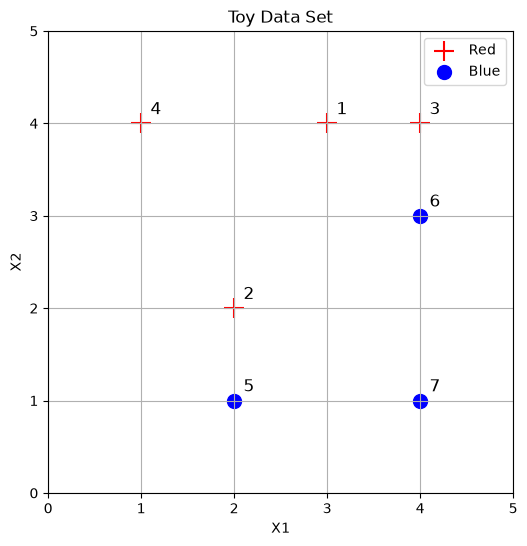

In [28]:
import matplotlib.pyplot as plt

# Data points
X1 = [3, 2, 4, 1, 2, 4, 4]
X2 = [4, 2, 4, 4, 1, 3, 1]
Y  = ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']

# Create the plot
plt.figure(figsize=(6, 6))

for i in range(len(Y)):
    if Y[i] == 'Red':
        plt.scatter(X1[i], X2[i], color='red', marker='+', s=200, label='Red' if i==0 else "")
    else:
        plt.scatter(X1[i], X2[i], color='blue', marker='o', s=100, label='Blue' if i==4 else "")

# Annotate the observation numbers
for i in range(len(Y)):
    plt.text(X1[i]+0.1, X2[i]+0.1, str(i+1), fontsize=12)

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Toy Data Set')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
## b.

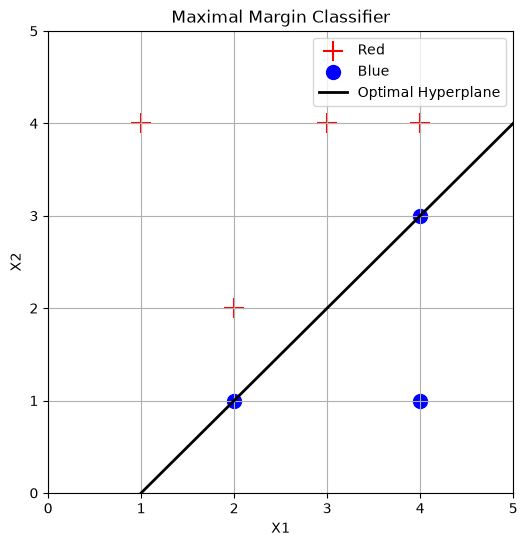

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Data points
X1 = [3, 2, 4, 1, 2, 4, 4]
X2 = [4, 2, 4, 4, 1, 3, 1]
Y  = ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']

# Plot points
plt.figure(figsize=(6, 6))
for i in range(len(Y)):
    if Y[i] == 'Red':
        plt.scatter(X1[i], X2[i], color='red', marker='+', s=200, label='Red' if i==0 else "")
    else:
        plt.scatter(X1[i], X2[i], color='blue', marker='o', s=100, label='Blue' if i==4 else "")


x_values = np.linspace(0, 5, 100)
y_values = x_values - 1
plt.plot(x_values, y_values, 'k-', linewidth=2, label='Optimal Hyperplane')

# Formatting
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Maximal Margin Classifier')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
## c.

In [ ]:
# The classification rule for the maximal margin classifier is based on the equation of the optimal hyperplane. 
# The values for the parameters are beta0 = 1, beta1 = -1, and beta2 = 1. Therefore, the rule is to classify an 
# observation as Red if 1 - X1 + X2 > 0, and classify it as Blue otherwise (if it is less than zero).

In [ ]:
## d.

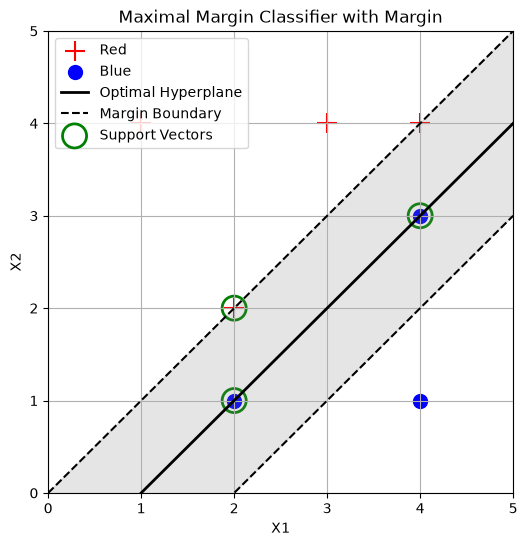

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Data points
X1 = [3, 2, 4, 1, 2, 4, 4]
X2 = [4, 2, 4, 4, 1, 3, 1]
Y  = ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']

plt.figure(figsize=(6, 6))
for i in range(len(Y)):
    if Y[i] == 'Red':
        plt.scatter(X1[i], X2[i], color='red', marker='+', s=200, label='Red' if i==0 else "")
    else:
        plt.scatter(X1[i], X2[i], color='blue', marker='o', s=100, label='Blue' if i==4 else "")

# Optimal hyperplane: X2 = X1 - 1
x_values = np.linspace(0, 5, 100)
plt.plot(x_values, x_values - 1, 'k-', linewidth=2, label='Optimal Hyperplane')

# Margin lines (dashed)
plt.plot(x_values, x_values, 'k--', label='Margin Boundary')
plt.plot(x_values, x_values - 2, 'k--')

# Highlight the support vectors
plt.scatter([2, 2, 4], [2, 1, 3], s=300, facecolors='none', edgecolors='green', linewidth=2, label='Support Vectors')

# Fill the margin area
plt.fill_between(x_values, x_values - 2, x_values, color='gray', alpha=0.2)

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Maximal Margin Classifier with Margin')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
## e.

In [ ]:
# The support vectors are the data points that lie exactly on the margin boundaries. In this dataset, 
# there are three support vectors: Observation 2 (X1 = 2, X2 = 2, Red), Observation 5 (X1 = 2, X2 = 1, Blue), 
# and Observation 6 (X1 = 4, X2 = 3, Blue). These points are the closest ones to the optimal separating hyperplane, 
# and they determine the exact position and width of the margin. If any other points were moved slightly, the hyperplane would not change.

In [ ]:
## f.

In [ ]:
# The seventh observation is the Blue point at (4, 1). This point is far away from the optimal hyperplane and the
# margin boundaries. The hyperplane is determined entirely by the support vectors, which are observations 2, 5, and 6. 
# Since observation 7 is not a support vector and is located safely on the correct side of the margin, a slight movement 
# of it will not cross the margin boundary or change the closest points. Therefore, the optimal hyperplane and the margin 
# will remain completely unchanged.

In [ ]:
## g.

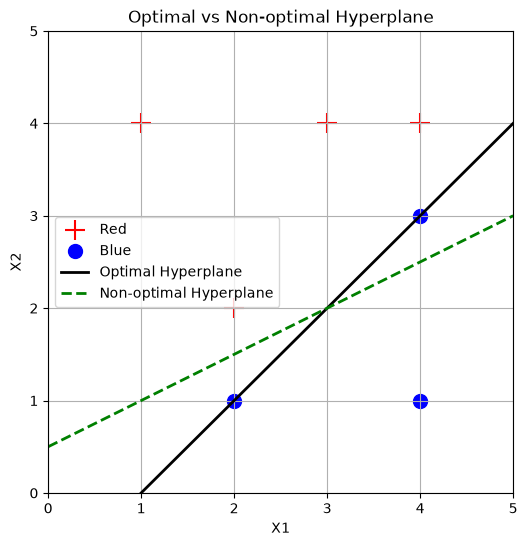

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Data points
X1 = [3, 2, 4, 1, 2, 4, 4]
X2 = [4, 2, 4, 4, 1, 3, 1]
Y  = ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']

plt.figure(figsize=(6, 6))
for i in range(len(Y)):
    if Y[i] == 'Red':
        plt.scatter(X1[i], X2[i], color='red', marker='+', s=200, label='Red' if i==0 else "")
    else:
        plt.scatter(X1[i], X2[i], color='blue', marker='o', s=100, label='Blue' if i==4 else "")

# Optimal hyperplane: X2 = X1 - 1
x_values = np.linspace(0, 5, 100)
plt.plot(x_values, x_values - 1, 'k-', linewidth=2, label='Optimal Hyperplane')

# Non-optimal hyperplane: -1 - X1 + 2*X2 = 0 => X2 = 0.5*X1 + 0.5
plt.plot(x_values, 0.5 * x_values + 0.5, 'g--', linewidth=2, label='Non-optimal Hyperplane')

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Optimal vs Non-optimal Hyperplane')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
## h.

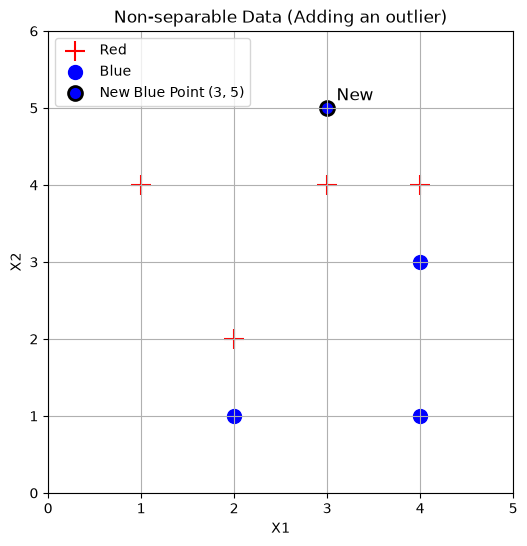

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# Original data points
X1 = [3, 2, 4, 1, 2, 4, 4]
X2 = [4, 2, 4, 4, 1, 3, 1]
Y  = ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']

plt.figure(figsize=(6, 6))

# Plot original points
for i in range(len(Y)):
    if Y[i] == 'Red':
        plt.scatter(X1[i], X2[i], color='red', marker='+', s=200, label='Red' if i==0 else "")
    else:
        plt.scatter(X1[i], X2[i], color='blue', marker='o', s=100, label='Blue' if i==4 else "")

# Add the new observation
plt.scatter(3, 5, color='blue', marker='o', s=100, edgecolor='black', linewidth=2, label='New Blue Point (3, 5)')
plt.text(3.1, 5.1, 'New', fontsize=12, color='black')

plt.xlim(0, 5)
plt.ylim(0, 6)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Non-separable Data (Adding an outlier)')
plt.legend()
plt.grid(True)
plt.show()